# Copy this notebook into usr/ and adjust to your needs.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [2]:
### setup ###

import sys
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results, select_reprseqs_to_display 
from utils.postprocess import load_features_data, select_features_to_display
from plots.plot_clustering_and_ecfs import plot_alignment_selected

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [3]:
# load dataset of hits with annotated clusters

clustering_results = load_clustering_results(workdir_path, mode='clusters')
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652820,reprseq35525,5,480,488,reprseq31745,3,457,487,23,590.9,4.200000e-72,100.0,6.400000e-76,0
652821,reprseq35525,5,467,488,reprseq18132,2,527,527,23,1126.4,6.000000e-140,100.0,9.000000e-144,0
652822,reprseq35525,6,466,488,reprseq21544,3,475,476,42,985.6,4.000000e-123,100.0,6.000000e-127,0
652823,reprseq35525,7,418,488,reprseq29665,18,412,432,15,321.6,1.900000e-37,100.0,2.900000e-41,0


In [4]:
# load features data
# features_to_load = ['hhblits-pfam', 'hhblits-uniclust', 'hhblits-phrogs', 'hhrepid']
features_to_load = ['hhblits-pfam']

features_data = load_features_data(workdir_path, features_to_load)
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)

hhblits-pfam


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq06167,18,118,301,PF10127.9,14,100,249,18,47.5,0.00089,93.4,2.500000e-07,PF10127.9 ; RlaP ; RNA repair pathway DNA poly...
1,reprseq06167,24,53,301,PF01909.23,10,39,91,33,34.4,0.00620,89.7,1.900000e-06,PF01909.23 ; NTP_transf_2 ; Nucleotidyltransfe...
2,reprseq06167,28,53,301,PF14091.6,18,43,150,19,35.5,0.06400,78.6,1.700000e-05,PF14091.6 ; DUF4269 ; Domain of unknown functi...
3,reprseq06167,22,53,301,PF03445.13,47,78,139,22,32.8,0.07000,77.1,2.000000e-05,PF03445.13 ; DUF294 ; Putative nucleotidyltran...
4,reprseq06167,22,104,301,PF12633.7,88,158,197,15,31.5,1.20000,40.5,2.900000e-04,PF12633.7 ; Adenyl_cycl_N ; Adenylate cyclase ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631722,reprseq20510,82,117,151,PF08326.12,40,87,743,19,28.5,4.10000,20.0,1.100000e-03,PF08326.12 ; ACC_central ; Acetyl-CoA carboxyl...
631723,reprseq35712,124,140,247,PF07460.11,3,19,37,47,38.8,0.00082,93.7,1.800000e-07,PF07460.11 ; NUMOD3 ; NUMOD3 motif (2 copies)
631724,reprseq35712,28,107,247,PF01541.24,2,86,86,22,37.5,0.00340,91.4,9.000000e-07,PF01541.24 ; GIY-YIG ; GIY-YIG catalytic domain
631725,reprseq09398,4,15,60,PF15103.6,45,56,103,42,22.9,2.50000,31.1,5.100000e-04,PF15103.6 ; G0-G1_switch_2 ; G0/G1 switch prot...


In [8]:
# TEMP - get qECF with various AHO
clustering_stats = load_clustering_results(workdir_path, mode='stats')
# various AHO
# sel = clustering_stats[(clustering_stats['avg_hits_overlap'] < 0.7) & (clustering_stats['nb_hits'] >= 40)]
# dis = [int(r.split('reprseq')[1]) for r in list(set(sel['qname'].to_list()))]
# sel

# Pfam and ECF
sel = clustering_stats[(clustering_stats['avg_hits_overlap'] >= 0.9) & (clustering_stats['nb_hits'] >= 40)]
dis = [int(r.split('reprseq')[1]) for r in list(set(sel['qname'].to_list()))]
sel

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength
34,reprseq30162,0,49,0.931661,186,0.891705,0.902913
39,reprseq27906,0,53,0.958989,390,0.879584,0.955882
42,reprseq32065,0,130,0.933028,84,0.842857,0.388889
64,reprseq13632,0,43,0.966939,329,0.940765,0.993958
73,reprseq33405,0,65,0.954829,507,0.934001,0.994118
...,...,...,...,...,...,...,...
21689,reprseq21375,0,62,0.913813,39,0.823408,0.382353
21712,reprseq03223,0,40,0.964692,168,0.942857,0.870466
21785,reprseq18652,0,40,0.957576,159,0.936792,1.000000
21808,reprseq06119,1,46,0.961383,218,0.893598,0.759582


In [16]:
# select representative proteins to display
reprseqs_to_display = [21869, 21131, 3445, 14815] # poster
reprseqs_to_display = [23093] # poster

reprseqs_to_display = [1457, 24843, 1945] # presentation MCB

# reprseqs_to_display = dis[:320]

# reprseqs_to_display = [72, 30989, 22103, 10133]
# reprseqs_to_display = [3888, 11069, 12827, 12827, 14391, 17969, 36416, 227, 27906,
#                        21805, 24843, 33085]


# filter reprseq & features data for plot
selected_reprseq_data  = select_reprseqs_to_display(clustering_results, reprseqs_to_display)
selected_features_data = select_features_to_display(features_data, reprseqs_to_display)

# show selected
display(selected_reprseq_data)
print('FEATURES:')
for fname, fdata in selected_features_data.items():
    print(fname)
    display(fdata)

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
198428,reprseq01457,13,347,373,reprseq18350,29,405,410,13,277.5,1.400000e-33,99.9,2.100000e-37,0
198429,reprseq01457,29,344,373,reprseq03005,22,373,384,13,479.7,1.400000e-61,100.0,2.000000e-65,0
198430,reprseq01457,29,335,373,reprseq20217,97,481,696,8,63.4,2.600000e-03,93.0,3.500000e-07,0
198431,reprseq01457,31,343,373,reprseq35193,15,377,822,8,258.2,3.300000e-28,99.9,5.000000e-32,0
198432,reprseq01457,32,345,373,reprseq27906,35,388,408,13,306.0,8.500000e-38,100.0,1.300000e-41,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652341,reprseq01945,3,143,771,reprseq04744,6,168,726,51,201.4,1.400000e-20,99.6,1.900000e-24,0
652342,reprseq01945,5,94,771,reprseq20897,11,146,714,40,77.3,9.500000e-05,95.6,1.200000e-08,0
652343,reprseq01945,6,101,771,reprseq20599,7,96,362,26,65.2,1.100000e-03,94.0,1.400000e-07,0
652344,reprseq01945,8,84,771,reprseq07799,12,96,1189,39,68.6,3.200000e-03,92.5,4.700000e-07,0


FEATURES:
hhblits-pfam


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
96587,reprseq24843,338,564,859,PF12708.7,2,227,229,17,122.8,7.200000e-13,98.7,1.800000e-16,PF12708.7 ; Pectate_lyase_3 ; Pectate lyase su...
96588,reprseq24843,355,600,859,PF01696.17,44,239,383,14,103.6,2.200000e-08,97.5,5.000000e-12,PF01696.17 ; Adeno_E1B_55K ; Adenovirus EB1 55...
96589,reprseq24843,356,637,859,PF07602.11,12,248,273,12,84.7,3.800000e-07,97.0,9.600000e-11,PF07602.11 ; DUF1565 ; Protein of unknown func...
96590,reprseq24843,357,404,859,PF12218.8,7,55,67,13,62.8,7.900000e-06,96.3,1.800000e-09,PF12218.8 ; End_N_terminal ; N terminal extens...
96591,reprseq24843,371,636,859,PF00295.17,3,237,318,10,77.8,1.400000e-05,96.1,3.300000e-09,PF00295.17 ; Glyco_hydro_28 ; Glycosyl hydrola...
96592,reprseq24843,358,534,859,PF01095.19,10,167,294,13,66.4,4.200000e-04,94.3,9.900000e-08,PF01095.19 ; Pectinesterase ; Pectinesterase
96593,reprseq24843,377,403,859,PF16318.5,5,29,138,8,54.9,1.400000e-03,93.0,3.300000e-07,PF16318.5 ; DUF4957 ; Domain of unknown functi...
96594,reprseq24843,445,564,859,PF13229.6,11,115,159,6,52.3,2.700000e-03,91.9,6.800000e-07,PF13229.6 ; Beta_helix ; Right handed beta hel...
96595,reprseq24843,466,636,859,PF13229.6,3,140,159,10,38.8,2.700000e-01,63.7,6.700000e-05,PF13229.6 ; Beta_helix ; Right handed beta hel...
96596,reprseq24843,549,563,859,PF16318.5,98,112,138,13,38.9,3.100000e-01,62.2,7.500000e-05,PF16318.5 ; DUF4957 ; Domain of unknown functi...


In [6]:
# TEMP - filter Pfam
dfpfam = selected_features_data['hhblits-pfam']
dfpfam = dfpfam[dfpfam['eval'] <= 1e-03]
selected_features_data['hhblits-pfam'] = dfpfam

In [18]:
# TEMP - get qECF with various AHO
clustering_stats[(clustering_stats['qname'] == 'reprseq01457')]

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength
7780,reprseq01457,0,28,0.963054,336,0.915179,0.900804
7781,reprseq01457,1,13,0.941154,132,0.938811,0.353887


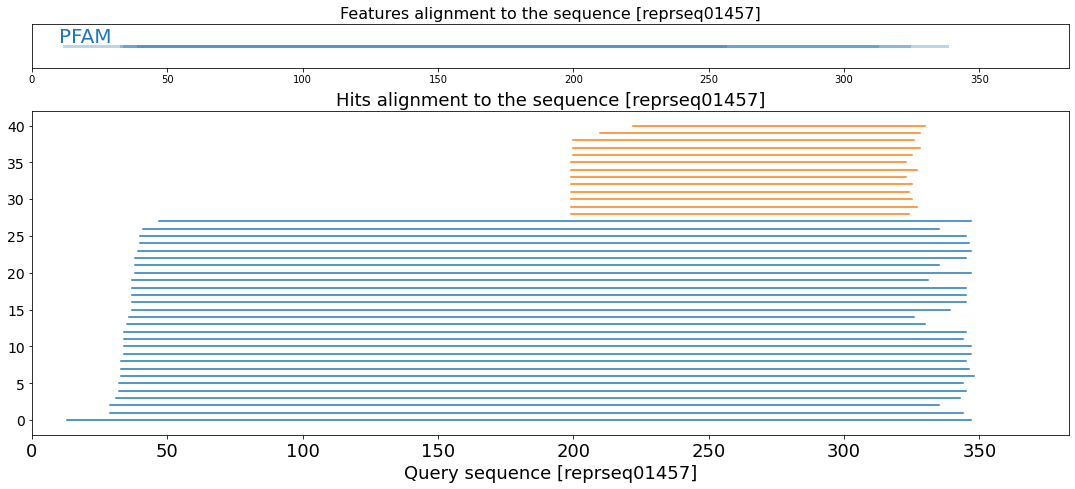

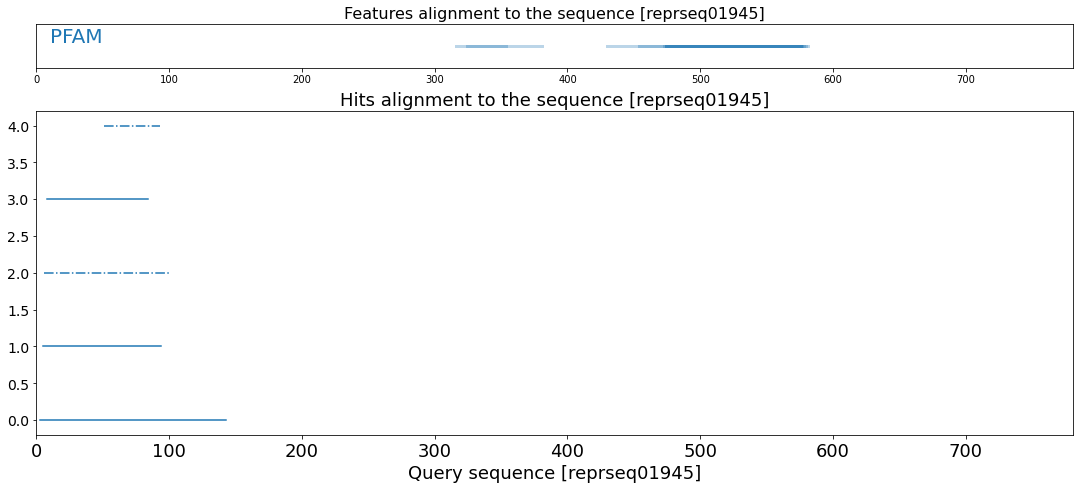

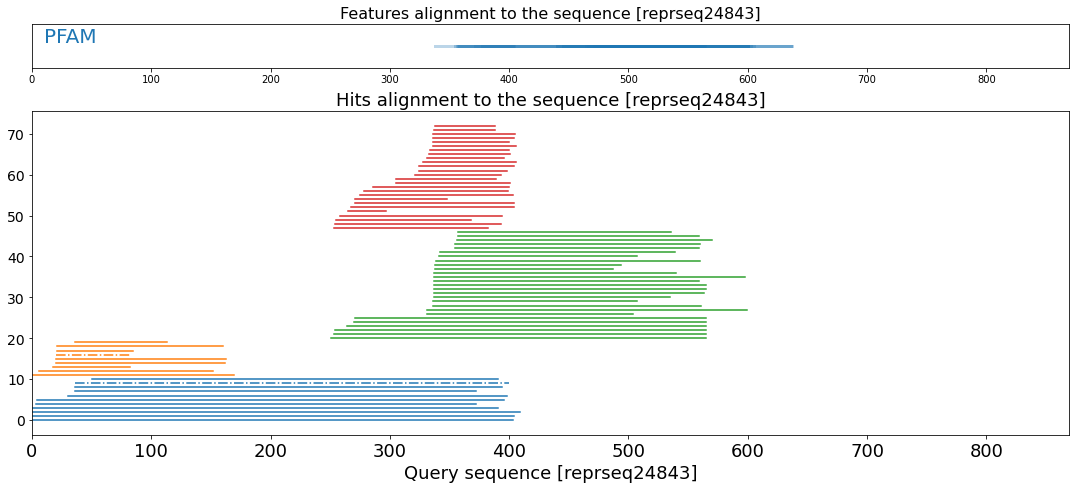

In [17]:
# plot required reprseqs
plot_alignment_selected(workdir_path, selected_reprseq_data, selected_features_data, save_figure=True)